#  Prophet

Before you start: upload `daily_sales.csv` to Colab.


The data is made up: three years of daily sales for a fictional shop.

If the Prophet import fails in Colab, run `%pip install prophet` in a cell, then rerun the imports.

In [1]:
import logging
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

In [2]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from prophet import Prophet

In [3]:
df = pd.read_csv("daily_sales.csv")
df["date"] = pd.to_datetime(df["date"])

In [4]:
df = df.sort_values("date").reset_index(drop=True)
if df["date"].isna().any() or df["date"].duplicated().any():
    raise ValueError("The  file must have one valid row per date.")
if not df["date"].equals(pd.Series(pd.date_range(df["date"].min(), df["date"].max(), freq="D"))):
    raise ValueError("The  file must contain consecutive daily dates.")

In [5]:
train = df.iloc[:-60]
test = df.iloc[-60:]

## Step 1: get the data into Prophet's format
The required columns are `ds` (date) and `y` (value).

We select just these two for this example;

Prophet can use additional columns.

In [6]:
train_p = train[["date", "sales"]].rename(columns={"date": "ds", "sales": "y"})
train_p.head()

,ds,y
0,2022-01-01,86
1,2022-01-02,179
2,2022-01-03,146
3,2022-01-04,163
4,2022-01-05,133


## Step 2: fit

In [7]:
model = Prophet(interval_width=0.8)
model.fit(train_p)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


## Step 3: make a table of future dates, then predict

In [8]:
future = model.make_future_dataframe(periods=60)
forecast = model.predict(future)

forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail()

,ds,yhat,yhat_lower,yhat_upper
1091,2024-12-27,380.384845,360.913828,400.749043
1092,2024-12-28,411.372052,390.092765,431.381575
1093,2024-12-29,394.845584,373.227810,414.619465
1094,2024-12-30,338.916065,318.456479,359.333387
1095,2024-12-31,357.197595,336.474704,379.707158


`yhat` is the forecast. `yhat_lower` and `yhat_upper` are the edges of the uncertainty band.

## Step 4: plot the last 60 days

In [9]:
future_part = forecast.tail(60)

fig = go.Figure()
fig.add_scatter(x=future_part["ds"], y=future_part["yhat_upper"], line=dict(width=0), showlegend=False)
fig.add_scatter(x=future_part["ds"], y=future_part["yhat_lower"], fill="tonexty",
                fillcolor="rgba(196,18,48,0.2)", line=dict(width=0), name="uncertainty band")
fig.add_scatter(x=future_part["ds"], y=future_part["yhat"], name="forecast", line=dict(color="#C41230"))
fig.add_scatter(x=test["date"], y=test["sales"], name="actual", line=dict(color="black"))
fig.update_layout(title="Prophet forecast vs actual")
fig.show()

## The four parts of Prophet
Prophet builds the forecast by adding four pieces together:

1. **Trend.** A line that can change direction. Prophet looks for the dates where the growth speeds up or slows down, and bends the line there.
2. **Yearly pattern.** A smooth curve that repeats every year.
3. **Weekly pattern.** One number for each day of the week.
4. **Holidays.** A list of special days. This list is the only part we have to give it ourselves.

Weekly and yearly seasonality are enabled automatically when there is enough history;

holidays require a supplied calendar.

This is the default additive setup, and Prophet also offers other settings.


Read documentation here: https://meta.github.io/prophet

## Step 5: look inside the model

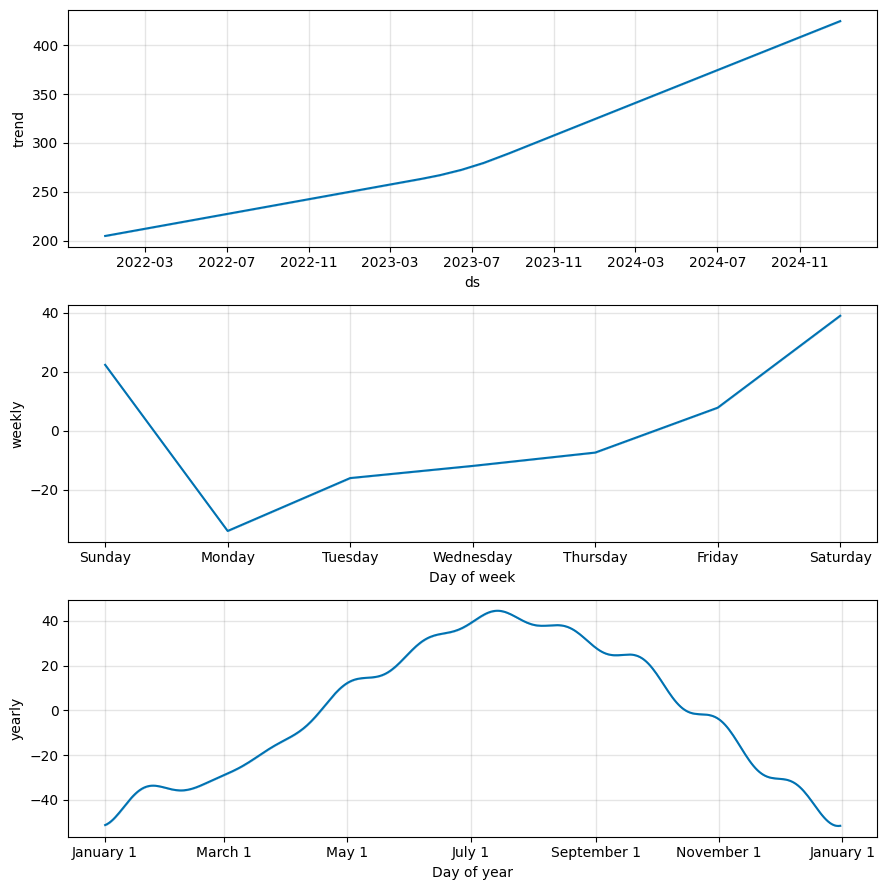

In [10]:
fig = model.plot_components(forecast)

## How good is it?
Same test period, same measure as before.

In [11]:
def mae(actual, predicted):
    return np.mean(np.abs(actual - predicted))

actual = test["sales"].values
prophet_mae = mae(actual, future_part["yhat"].values)
print("Prophet MAE:", round(prophet_mae, 1))

Prophet MAE: 18.2


## Check interval coverage
How many actual values fall inside the nominal 80% prediction interval? One 60-day window provides limited evidence. Check coverage across several forecast origins and horizons; close coverage here does not establish calibration.

In [12]:
inside = (actual >= future_part["yhat_lower"].values) & (actual <= future_part["yhat_upper"].values)
print("Days inside the band:", inside.sum(), "out of 60")

Days inside the band: 50 out of 60


## Teach Prophet about holidays
One extra line tells Prophet that holidays are special days.

In [13]:
model2 = Prophet(interval_width=0.8)
model2.add_country_holidays(country_name="US")
model2.fit(train_p)

forecast2 = model2.predict(model2.make_future_dataframe(periods=60))
prophet_hol_mae = mae(actual, forecast2["yhat"].tail(60).values)
print("Prophet with holidays MAE:", round(prophet_hol_mae, 1))

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Prophet with holidays MAE: 11.2


## Everything side by side
The two baselines again, then all the results in one table.

In [14]:
naive = np.repeat(train["sales"].iloc[-1], 60)
seasonal_naive = np.tile(train["sales"].iloc[-7:].values, 9)[:60]

results = pd.DataFrame({
    "method": ["naive", "seasonal naive", "Prophet", "Prophet + holidays"],
    "MAE": [mae(actual, naive), mae(actual, seasonal_naive), prophet_mae, prophet_hol_mae],
})
results["MAE"] = results["MAE"].round(1)
results

,method,MAE
0,naive,31.8
1,seasonal naive,24.3
2,Prophet,18.2
3,Prophet + holidays,11.2


MAE is the average absolute error, in units of sales.

From the previous notebook:

SARIMA 28.4

SARIMA with lags chosen by AIC 16.4

SARIMAX with holidays at the same order 11.6.

Prophet gets 18.2 without holidays and 11.2 with them.

This does not establish that Prophet generally outperforms SARIMA.
With well-chosen lags and the same holiday information, SARIMAX reaches about the same accuracy as Prophet.

Prophet gets there with less work.

## One test period can mislead
So far, we have tested every method on one period: the last 60 days. Those 60 days include Thanksgiving and Christmas, which are hard to predict. What if we had picked a different 60 days? The score might look very different.

Prophet has a built-in way to check this. It repeats the test several times:

1. Train on the data up to a certain date.
2. Forecast the next 60 days and compare with what really happened.
3. Move that date forward and do it again.

This gives us several scores instead of one.

We run it on the training data only, so the final 60 days stay untouched.

###In a real project

First set aside the final stretch of data and leave it alone.

Compare and choose your models on the earlier data, using repeated tests like these.

Only when you are done choosing, test the winner on the final stretch.

In [15]:
from prophet.diagnostics import cross_validation

df_cv = cross_validation(model, initial="730 days", period="60 days", horizon="60 days")
df_cv.head()

INFO:prophet:Making 5 forecasts with cutoffs between 2024-01-06 00:00:00 and 2024-09-02 00:00:00


  0%|          | 0/5 [00:00<?, ?it/s]

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2024-01-07,294.312493,270.085334,316.837542,321,2024-01-06
1,2024-01-08,239.335763,216.063136,262.498923,267,2024-01-06
2,2024-01-09,259.929634,237.227917,284.031337,253,2024-01-06
3,2024-01-10,264.543414,242.537314,287.893513,251,2024-01-06
4,2024-01-11,268.641137,243.291675,290.939795,295,2024-01-06


`initial` is how much data to train on first, `period` is how far to move the cutoff each time, and `horizon` is how far ahead to forecast. Each `cutoff` is one test.

In [16]:
cv_results = df_cv.assign(abs_error=(df_cv["y"] - df_cv["yhat"]).abs()).groupby("cutoff", as_index=False).agg(MAE=("abs_error", "mean"))
cv_results["MAE"] = cv_results["MAE"].round(1)
cv_results

,cutoff,MAE
0,2024-01-06,14.5
1,2024-03-06,9.7
2,2024-05-05,9.6
3,2024-07-04,9.7
4,2024-09-02,8.1


Compare the observed MAEs across cutoffs with the final-period MAE. Different windows can have different difficulty. The final period includes Thanksgiving and Christmas, which may contribute to errors without holiday features, but the score differences alone do not prove that explanation.

These windows assess plain Prophet only. For model selection, compare all candidate models and baselines on matching cutoffs before opening a final holdout.

## From a forecast to a business decision
Suppose running out of stock costs much more than having leftovers. Would you order the point forecast or something higher? What additional information would you need?

